<a href="https://colab.research.google.com/github/ibonetc/IA_2026/blob/main/ML_Regresion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión

## Regresión Lineal

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

Generar conjunto de números aleatorios

In [ ]:
np.random.seed(0)
#Números con distribución uniforme en el intervalo [0, 1)
x = np.random.rand(1000, 1) # Se le pasa como parámetro las dimensiones del arreglo
y = 2 + 3 * x + np.random.rand(1000, 1)

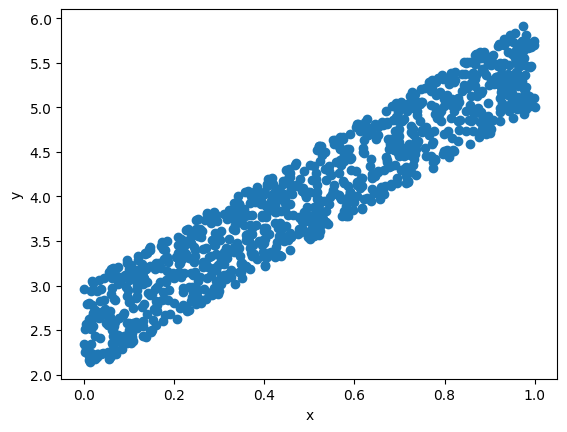

In [ ]:
plt.scatter(x,y)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Model initialization
regression_model = LinearRegression()

In [ ]:
# Fit the data(train the model)
regression_model.fit(x, y)

LinearRegression()

In [ ]:
# Predict
y_predicted = regression_model.predict(x)

In [ ]:
# model evaluation
rmse = mean_squared_error(y, y_predicted)
r2 = r2_score(y, y_predicted)

In [ ]:
# printing values
print('Slope:' ,regression_model.coef_)
print('Intercept:', regression_model.intercept_)
print('Root mean squared error: ', rmse)
print('R2 score: ', r2)

Slope: [[3.00618965]]
Intercept: [2.50828041]
Root mean squared error:  0.08937277533486776
R2 score:  0.8951689909999495


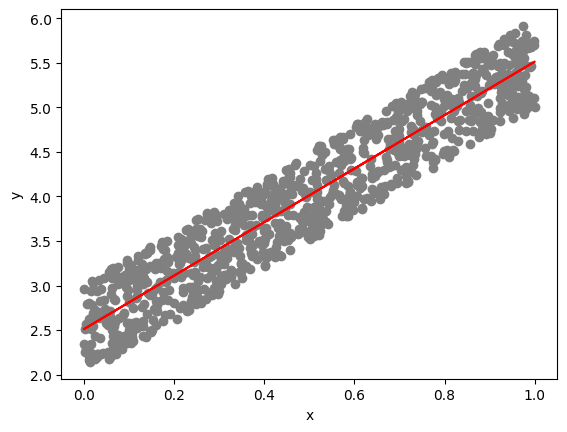

In [ ]:
# plotting values

# data points
plt.scatter(x, y, color='gray')
plt.xlabel('x')
plt.ylabel('y')

# predicted values
plt.plot(x, y_predicted, color='r')
plt.show()

## Ejemplo con Base de datos Boston


**CRIM** - Crimen per cápita por ciudad

**ZN** - proporción de terrenos residenciales divididos en zonas para lotes de más de 25,000 pies cuadrados

**INDUS** - proporción de acres de negocios no minoristas por ciudad

**CHAS** - variable ficticia de Charles River (= 1 si el tramo limita el río, 0 de lo contrario)

**NOX** - concentración de óxidos nítricos (partes por 10 millones)

**RM** - número promedio de habitaciones por vivienda

**AGE** - proporción de unidades ocupadas por sus propietarios construidas antes de 1940

**DIS** - Distancias desproporcionadas a cinco centros de empleo de Boston

**RAD** - índice de accesibilidad a las autopistas radiales

**TAX** - tasa de impuesto a la propiedad de valor completo por USD 10,000

**PTRATIO** - colegios por localidad

**B** 1000 (B - 0,63)^ 2, donde B es la proporción de negros por ciudad

**LSTAT** - porcentaje de estado inferior de la población

**MEDV** - valor mediano de las viviendas ocupadas por sus propietarios en USD 1000



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing()

In [ ]:
california=pd.DataFrame(housing.data, columns=housing.feature_names)

In [ ]:
dataset = load_boston()
boston = pd.DataFrame(dataset.data, columns=dataset.feature_names)

In [ ]:
california.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='object')

In [ ]:
boston['MEDV'] = dataset.target

In [ ]:
boston.head()

In [ ]:
boston.info()

In [ ]:
boston.describe()


In [ ]:
sns.pairplot(boston)

### Histogramas de una sola variable

In [ ]:
boston.columns

In [ ]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.distplot(boston['MEDV'])
plt.subplot(1,2,2)
sns.distplot(boston['CRIM'])
plt.tight_layout()

In [ ]:
boston.corr()

In [ ]:
plt.figure(figsize=(10,10))
sns.heatmap(boston.corr().round(2), annot = True)

La matriz de correlación puede ser una base para seleccionar las variables para el modelo de regresión.

Si observamos la correlación de las variables con la variable objetivo (MEDV), vemos por ejemplo que RM tiene una fuerte correlación positiva con MEDV (0.7), mientras que LSTAT tiene una alta correlación negativa con MEDV (-0.74).


También se puede verificar la multicolinealidad. Las características RAD, TAX tienen una correlación de 0.91. Estos pares de características están fuertemente correlacionados entre sí. No debemos seleccionar estas dos características juntas para entrenar el modelo.

Lo mismo ocurre con las características DIS y AGE que tienen una correlación de -0.75.

In [ ]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2 , 1)
plt.scatter(boston['LSTAT'], boston['MEDV'], marker='o')
plt.title('LSTAT')
plt.xlabel('LSTAT')
plt.ylabel('MEDV')

plt.subplot(1, 2 , 2)
plt.scatter(boston['RM'], boston['MEDV'], marker='o')
plt.title('RM')
plt.xlabel('RM')
plt.ylabel('MEDV')

## Entrenar el modelo de Regresión Lineal

In [ ]:
boston.columns

In [ ]:
dataset = boston.values
X=boston.iloc[:,0:-1]

In [ ]:
X.head()

In [ ]:
Y=boston['MEDV']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=5)

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lr = LinearRegression()

In [ ]:
lr.fit(X_train, Y_train)

In [ ]:
print(lr.intercept_)

In [ ]:
lr.coef_

In [ ]:
coeff_df = pd.DataFrame(lr.coef_, X.columns, columns=['W'])
coeff_df

### Conclusiones de la regresión
¿Cómo interpretar estos resultados?
Como se ha dicho, la regresión puede servir para ver relación entre las variables independientes y la variable dependiente (Precio).

Según el resutlado de esos coeficientes o pesos de la regresión lineal, podemos ver, por ejemplo que:
- Si se mantienen todas las variables fijas, el cambio de una unidad en la variable **CRI**, esto se reflejará en $130.8 (0.1308 *1000) de disminución del precio.

Y así con el resto de las variables.

## Predicción

In [ ]:
predictions = lr.predict(X_test)

In [ ]:
df = pd.DataFrame({'Actual': Y_test, 'Predicted': predictions, 'Dif': Y_test-predictions})
df

In [ ]:
plt.scatter(Y_test, predictions)

plt.plot(Y_test, Y_test, color='r')

Histograma de los residuos

In [ ]:
sns.distplot((Y_test - predictions), bins = 50,color='Blue')

In [ ]:
from sklearn import metrics

El coeficiente de determinación R2 es la fracción (porcentaje) de variación en la variable de respuesta Y que es explicable por la variable de predicción X. Oscila entre 0 (sin previsibilidad) a 1 (o 100%) lo que indica una previsibilidad completa. Un R2 alto indica ser capaz de predecir la variable de respuesta con menos error.

In [ ]:
print('MAE:', metrics.mean_absolute_error(Y_test, predictions))
print('MSE:', metrics.mean_squared_error(Y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(Y_test, predictions)))
print('R2:',r2_score(Y_test, predictions))

## Seleccionando rasgos
Si minimizamos los atributos, basado en la matriz de correlación anterior:

In [ ]:
X = pd.DataFrame(np.c_[boston['LSTAT'], boston['RM']], columns = ['LSTAT','RM'])
Y = boston['MEDV']

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state=5)

In [ ]:
lr = LinearRegression()
lr.fit(X_train,Y_train)

In [ ]:
coeff_df = pd.DataFrame(lr.coef_, X.columns, columns=['W'])
coeff_df

In [ ]:
predictions=lr.predict(X_test)
predictions_train=lr.predict(X_train)
print('Train---------------------')
print('RMSE:', np.sqrt(metrics.mean_squared_error(Y_train, predictions_train)))
print('R2:',r2_score(Y_train, predictions_train))
print('Test---------------------')
print('RMSE:', np.sqrt(metrics.mean_squared_error(Y_test, predictions)))
print('R2:',r2_score(Y_test, predictions))

### Validación Cruzada

In [ ]:
lr = LinearRegression()
lr.fit(X, Y)
pred = lr.predict(X)
print('RMSE:', np.sqrt(metrics.mean_squared_error(Y, pred)))
print('R2:',r2_score(Y, pred))

In [ ]:
from sklearn.model_selection import KFold,cross_validate, cross_val_score, cross_val_predict
from sklearn import metrics

In [ ]:
metrics.SCORERS.keys()

In [ ]:
cv=cross_validate(lr,X_train,Y_train,scoring=['neg_mean_squared_error','r2'], cv=10)

In [ ]:
np.mean(cv['test_r2'])

In [ ]:
predictions = cross_val_predict(lr, X, Y, cv=10)
plt.scatter(Y, predictions)

#### Usando KFold

In [ ]:
lr = LinearRegression()
n_fold=10
k_folds=KFold(n_splits=n_fold)
scores=[]
r2=[]
for train_index, test_index in k_folds.split(X_train):
  lm= lr.fit(X_train.iloc[train_index],Y_train.iloc[train_index])
  y_hat=lm.predict(X_train.iloc[test_index])
  scores.append(metrics.mean_squared_error(Y_train.iloc[test_index], y_hat))
  r2.append(r2_score(Y_train.iloc[test_index], y_hat))
mean_scores= np.mean(scores)
mean_r2= np.mean(r2)
print(mean_r2, mean_scores)

In [ ]:
cv=cross_val_score(lr,X_train,Y_train,scoring='r2' ,cv=k_folds)

In [ ]:
cv

In [ ]:
np.mean(cv)

## Regresión Polinomial

In [ ]:
from math import pi

np.random.seed(7)
#Números con distribución uniforme en el intervalo [0, 1)
x = np.random.rand(1000, 1) # Se le pasa como parámetro las dimensiones del arreglo
y=np.sin(2*pi*x)
mu, sigma = 0.1, 0.4 #media y desviación estándar
a=np.random.normal(mu, sigma, 1000)

y=y+a.reshape(-1,1)

In [ ]:
plt.scatter(x,y)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [ ]:
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)
plt.scatter(x, y, s=10)
plt.plot(x, y_pred, color='r')
plt.show()

In [ ]:
print('RMSE:', np.sqrt(metrics.mean_squared_error(y, y_pred)))
print('R2:',r2_score(y, y_pred))

### Utlizando la regresión polinomial
Una forma de buscar otra opción de ajuste de los valores, puede ser utilizanedo un ajuste polinomial, por ejemplo de grado 2,
En ese caso sería buscar una función:

f=w0+w1x^2

Por lo que lo que hay que tranformar es la variable x, para eso podemos utilizar la clase la clase **PolynomialFeatures** de la biblioteca **scikit-learn**.

De esta manera, al transformar la variable, entonces podemos utilizar de nuevo la regresión lineal, pues ya la variable está exponencial.


In [ ]:
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
polynomial_features= PolynomialFeatures(degree=2)
x_poly = polynomial_features.fit_transform(x)

In [ ]:
x_poly

En este caso que es una sola variable, es lo mismo que elevarla al cuadrado.

In [ ]:
pd.DataFrame({'x':x.flatten(),'x_poly':x_poly[:,2], 'x2':x.flatten()**2})

In [ ]:
model = LinearRegression()
model.fit(x_poly, y)
y_poly_pred = model.predict(x_poly)

rmse = np.sqrt(mean_squared_error(y,y_poly_pred))
r2 = r2_score(y,y_poly_pred)
print(rmse)
print(r2)

In [ ]:
import operator
plt.scatter(x, y)
# Ordenar valores de x
sort_axis = operator.itemgetter(0)
sorted_zip = sorted(zip(x,y_poly_pred), key=sort_axis)
x1, y_poly_pred = zip(*sorted_zip)
plt.plot(x1, y_poly_pred, color='red')
plt.show()

In [ ]:
polynomial_features= PolynomialFeatures(degree=3)
x_poly = polynomial_features.fit_transform(x)
model = LinearRegression()
model.fit(x_poly, y)
y_poly_pred = model.predict(x_poly)

rmse = np.sqrt(mean_squared_error(y,y_poly_pred))
r2 = r2_score(y,y_poly_pred)
print(rmse)
print(r2)
plt.scatter(x, y)
# Ordenar valores de x
sort_axis = operator.itemgetter(0)
sorted_zip = sorted(zip(x,y_poly_pred), key=sort_axis)
x1, y_poly_pred = zip(*sorted_zip)
plt.plot(x1, y_poly_pred, color='red')
plt.show()